# Summed Unimodal FER Confusion Matrices

Plot the summed static and dynamic unimodal confusion matrices for Figure 7.15 in Section 7.3.3 of the thesis.

The counts are hardcoded below. The plotting function uses the same settings as `dynamic_confusion_matrices.ipynb`, including the colour scale, fonts, annotations, dimensions, and PDF export.

Requirements: NumPy and Matplotlib. Run all cells in order. The two PDFs are saved in the working directory.


In [1]:
import numpy as np
import matplotlib.pyplot as plt

CLASS_NAMES = ["Anger", "Disgust", "Fear", "Happiness", "Neutral", "Sadness", "Surprise"]


## Source matrices

The hardcoded matrices correspond to Figures 7.2, 7.4, 7.9, and 7.11 of the thesis. Rows represent true classes and columns represent predicted classes, both in the order given in `CLASS_NAMES`.

- [Static image baseline (EmoHeVRDB-SI)](https://github.com/thorbenortmann/emoji-hero-vr-database/blob/main/vii_baseline/b_training_c_results/emohevrdb/emojihero_transfer_imagenet_20240320-1526/confusion_matrix.png)
- [Static FEA baseline, selected MLP (EmoHeVRDB-SFEA)](https://github.com/thorbenortmann/emohevrdb-sfer/blob/main/iii_unimodal_facial_expression_recognition/b_c_training_results/tensorflow/20241031-1748-checkpoint-batch-32-lr-1e-03_val_8155_test_7169/confusion_matrix.png)
- [Dynamic image baseline (EmoHeVRDB-DI)](https://github.com/thorbenortmann/emohevrdb-dfer/blob/3993b6813443e75eff8f380e9d4c1b1d6810221c/5_dynamic_facial_expression_recognition/5_1_image/confusion_matrix.png)
- [Dynamic FEA baseline (EmoHeVRDB-DFEA)](https://github.com/thorbenortmann/emohevrdb-dfer/blob/3993b6813443e75eff8f380e9d4c1b1d6810221c/5_dynamic_facial_expression_recognition/5_2_fea/confusion_matrix.png)


In [2]:
static_image = np.array([
    [55, 32,  2,  8,  4,  5,  2],
    [ 7, 74,  2, 19,  2,  2,  2],
    [ 0, 15, 68,  8,  6,  4,  7],
    [ 8,  3,  1, 93,  3,  0,  0],
    [14,  4,  0,  5, 81,  4,  0],
    [31,  3,  0,  0,  7, 67,  0],
    [ 1,  1, 14,  0,  1,  1, 90],
])

dynamic_image = np.array([
    [50, 45,  3,  3,  5,  2,  0],
    [ 8, 74,  3, 18,  1,  3,  1],
    [ 0, 18, 71,  8,  4,  0,  7],
    [ 6,  2,  1, 99,  0,  0,  0],
    [12,  1,  0,  4, 81, 10,  0],
    [15,  3,  0,  0,  2, 88,  0],
    [ 0,  1, 19,  0,  0,  1, 87],
])

static_fea = np.array([
    [26, 22,  1,  1,  4,  0,  0],
    [ 4, 33,  4,  8,  0,  2,  3],
    [ 0,  3, 31,  3,  6,  0, 11],
    [ 0,  0,  1, 53,  0,  0,  0],
    [ 0,  1,  5,  2, 45,  1,  0],
    [ 7,  1,  2,  0,  8, 36,  0],
    [ 0,  1,  4,  0,  2,  0, 47],
])

dynamic_fea = np.array([
    [28, 23,  1,  0,  2,  0,  0],
    [ 2, 30,  7, 10,  1,  2,  2],
    [ 0,  3, 33,  4,  6,  0,  8],
    [ 0,  0,  0, 54,  0,  0,  0],
    [ 0,  1,  0,  2, 51,  0,  0],
    [ 0,  4,  1,  0,  1, 48,  0],
    [ 0,  1,  1,  0,  0,  0, 52],
])


## Sum static and dynamic counts

Add the static and dynamic matrices within each modality. The image panel contains 1,512 sample evaluations, with two camera views per reenactment. The FEA panel contains 756 sample evaluations, with each reenactment counted once within each condition.


In [3]:
matrices = {
    "image_confusion_matrix.pdf": static_image + dynamic_image,
    "fea_confusion_matrix.pdf": static_fea + dynamic_fea,
}


## Plot and export


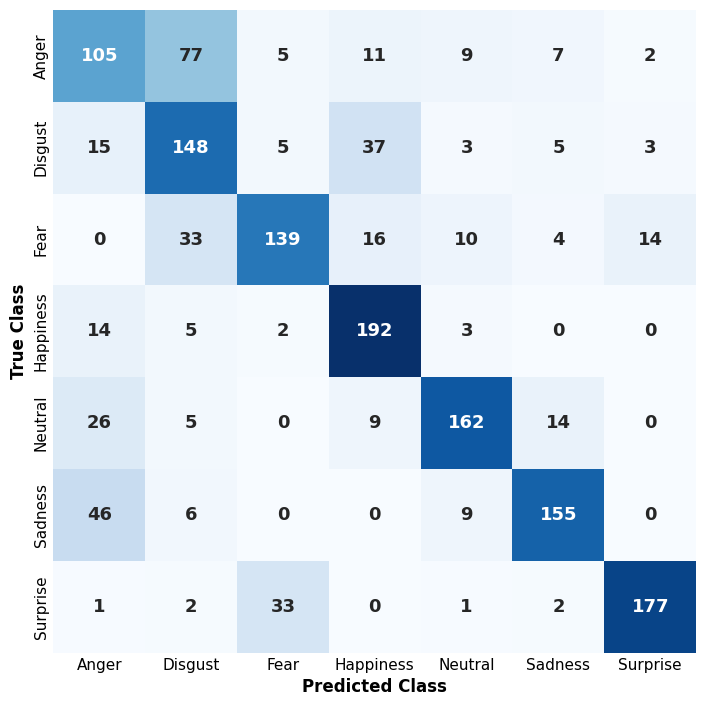

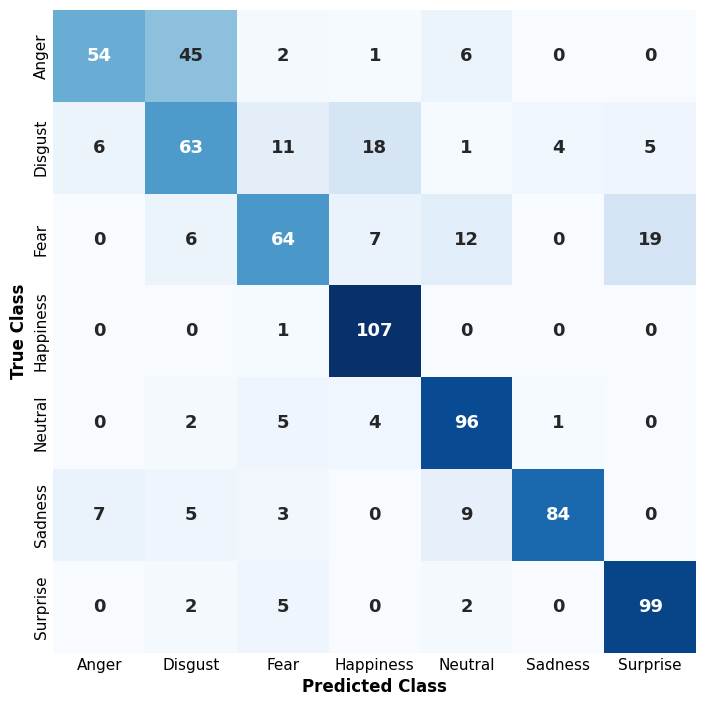

In [4]:
def plot_confusion_matrix(matrix, filename):
    with plt.rc_context({"font.family": "DejaVu Sans", "pdf.fonttype": 3}):
        fig, ax = plt.subplots(figsize=(7, 7))
        ax.pcolormesh(matrix, cmap="Blues", vmin=0, vmax=matrix.max(), shading="flat")
        ax.set_xlim(0, 7)
        ax.set_ylim(7, 0)
        ax.set_aspect("equal")

        positions = np.arange(7) + 0.5
        ax.set_xticks(positions, CLASS_NAMES, fontsize=11)
        ax.set_yticks(positions, CLASS_NAMES, fontsize=11, rotation=90, va="center")
        ax.set_xlabel("Predicted Class", fontsize=12, fontweight="bold")
        ax.set_ylabel("True Class", fontsize=12, fontweight="bold")
        ax.tick_params(axis="both", length=0)
        for spine in ax.spines.values():
            spine.set_visible(False)

        threshold = matrix.max() / 2
        for row in range(7):
            for column in range(7):
                value = matrix[row, column]
                ax.text(
                    column + 0.5, row + 0.5, str(value),
                    ha="center", va="center", fontsize=13, fontweight="bold",
                    color="white" if value > threshold else "#262626",
                )

        fig.tight_layout(pad=0.5)
        fig.savefig(filename, format="pdf", bbox_inches="tight", pad_inches=0.02)
        plt.show()
        plt.close(fig)


for filename, matrix in matrices.items():
    plot_confusion_matrix(matrix, filename)